# Integrated Business Analytics Project
**Data Analyst Internship · Task 4 · Phase 4**

One real dataset, six tools, one story. The same extract of the UCI *Online Retail* dataset (DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33)) is pushed through a complete professional workflow.

| # | Stage | Tool | Where the evidence lives |
|---|---|---|---|
| 1 | Explore | Python / pandas | this notebook |
| 2 | Clean & preprocess | pandas | this notebook |
| 3 | Load to database | MySQL / MariaDB | `SQL_Lab/load_data.py` |
| 4 | Analytical queries | SQL | `SQL_Lab/outputs/query_*.txt` |
| 5 | Spreadsheet analysis | Excel | `Excel_Lab/Excel_Data_Analysis_Lab.xlsx` |
| 6 | Visualisation | Matplotlib / Seaborn / Plotly | `Data_Visualization_Lab/outputs/` |
| 7 | Interactive dashboard | Power BI | `PowerBI_Lab/` build guide |
| 8 | Documented workflow | Jupyter | `Jupyter_Lab/` |
| 9 | Version control | Git / GitHub | `Git_GitHub_Lab/` |
| 10 | Findings & recommendations | all of the above | this notebook |

**Stages 1, 2, 4 and 6 are executed live below.** Stages 3, 5, 7, 8 and 9 are delivered as standalone artefacts, referenced with their real paths.

## Stage 1-2 · Explore and clean with pandas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymysql

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CSV = "../data/online_retail_sales_sample.csv"
df = pd.read_csv(CSV, parse_dates=["InvoiceDate"],
                 dtype={"InvoiceNo": str, "StockCode": str})
print(f"loaded {len(df):,} lines / {df['InvoiceNo'].nunique()} invoices")
df.head()

loaded 12,177 lines / 500 invoices


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,line_total
0,536572,21523,DOORMAT FANCY FONT HOME SWEET HOME,10,2010-12-01 15:40:00,6.75,"16,539.00",United Kingdom,67.50
1,536572,21754,HOME BUILDING BLOCK WORD,6,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,35.70
2,536572,21756,BATH BUILDING BLOCK WORD,3,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,17.85
3,536572,21810,CHRISTMAS HANGING STAR WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00
4,536572,21811,CHRISTMAS HANGING HEART WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00


In [2]:
df = df.drop_duplicates()
df["Country"] = df["Country"].str.strip().str.title()
df["Description"] = df["Description"].str.strip().str.upper()
df["month"] = df["InvoiceDate"].dt.strftime("%Y-%m")
df["revenue"] = (df["Quantity"] * df["UnitPrice"]).round(2)
df["high_value"] = (df["revenue"] >= 50).astype(int)
print(f"after cleaning: {len(df):,} lines, GBP {df['revenue'].sum():,.2f}")
df.groupby("month")["revenue"].sum().round(2)

after cleaning: 12,177 lines, GBP 239,642.62


month
2010-12    9,500.83
2011-01   35,715.76
2011-02   15,521.19
2011-03   13,521.09
2011-04   14,336.64
2011-05   15,081.58
2011-06   21,515.22
2011-07   10,663.94
2011-08   10,428.93
2011-09   23,704.43
2011-10   27,574.26
2011-11   25,334.51
2011-12   16,744.24
Name: revenue, dtype: float64

## Stage 3-4 · Load into MySQL and query with SQL
`SQL_Lab/run_sql_lab.py` creates the `retail_analytics` schema and loads the normalised tables. The same connection is used here so the integrated project and the SQL lab share one database.

In [3]:
conn = pymysql.connect(**{'host': '127.0.0.1', 'port': 3306, 'user': 'analyst', 'password': 'Analyst@2026', 'database': 'retail_analytics', 'charset': 'utf8mb4'})
q = '''
SELECT o.country,
       COUNT(DISTINCT o.invoice_no) AS orders,
       ROUND(SUM(oi.line_total), 2)  AS revenue_gbp
FROM orders o
INNER JOIN order_items oi ON oi.invoice_no = o.invoice_no
GROUP BY o.country
ORDER BY revenue_gbp DESC
LIMIT 8
'''
country = pd.read_sql(q, conn)
print(country.to_string(index=False))

       country  orders  revenue_gbp
United Kingdom     411   170,007.68
          EIRE      10     9,744.36
     Australia       3     7,948.54
        France      14     6,331.27
       Germany      10     6,201.41
         Spain       5     3,340.18
   Netherlands       4     3,182.22
       Belgium       3     1,582.69


/tmp/ipykernel_6008/2306997580.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  country = pd.read_sql(q, conn)


In [4]:
q2 = '''
WITH monthly AS (
    SELECT DATE_FORMAT(o.invoice_date, '%Y-%m') AS month,
           ROUND(SUM(oi.line_total), 2) AS revenue_gbp
    FROM orders o INNER JOIN order_items oi ON oi.invoice_no = o.invoice_no
    GROUP BY DATE_FORMAT(o.invoice_date, '%Y-%m')
)
SELECT month, revenue_gbp,
       ROUND(revenue_gbp / SUM(revenue_gbp) OVER () * 100, 2) AS pct
FROM monthly ORDER BY month
'''
monthly = pd.read_sql(q2, conn)
monthly

/tmp/ipykernel_6008/1035320660.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly = pd.read_sql(q2, conn)


,month,revenue_gbp,pct
0,2010-12,"9,451.39",4.45
1,2011-01,"30,468.44",14.35
2,2011-02,"13,178.41",6.21
3,2011-03,"10,242.71",4.82
4,2011-04,"13,903.31",6.55
5,2011-05,"15,081.58",7.10
6,2011-06,"17,267.71",8.13
7,2011-07,"10,244.92",4.82
8,2011-08,"8,069.03",3.80
9,2011-09,"23,704.43",11.16


In [5]:
q3 = '''
SELECT p.stock_code, p.description,
       ROUND(SUM(oi.line_total), 2) AS revenue_gbp
FROM order_items oi INNER JOIN products p ON p.stock_code = oi.stock_code
GROUP BY p.stock_code, p.description
ORDER BY revenue_gbp DESC LIMIT 5
'''
top_products = pd.read_sql(q3, conn)
print(top_products.to_string(index=False))
conn.close()

stock_code                        description  revenue_gbp
    85123A WHITE HANGING HEART T-LIGHT HOLDER     6,497.75
     22470              HEART OF WICKER LARGE     4,658.14
     22469              HEART OF WICKER SMALL     3,132.88
     21733   RED HANGING HEART T-LIGHT HOLDER     3,028.30
     22423           REGENCY CAKESTAND 3 TIER     2,778.60


/tmp/ipykernel_6008/2372584531.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_products = pd.read_sql(q3, conn)


## Stage 5 · Spreadsheet analysis
`Excel_Lab/Excel_Data_Analysis_Lab.xlsx` holds the same data with live formulas. Its KPIs were recalculated with LibreOffice and matched pandas to the penny (`Excel_Lab/evidence/excel_verification.txt`):

| KPI | Value |
|---|---:|
| Total revenue (UK) | 196,462.03 |
| Line items (UK) | 10,787 |
| Units sold (UK) | 108,560 |
| Orders (UK) | 442 |

The workbook also contains a formula-driven Pivot_View and an interactive KPI dashboard with a country slicer, conditional formatting and three charts.

## Stage 6 · Visualisation

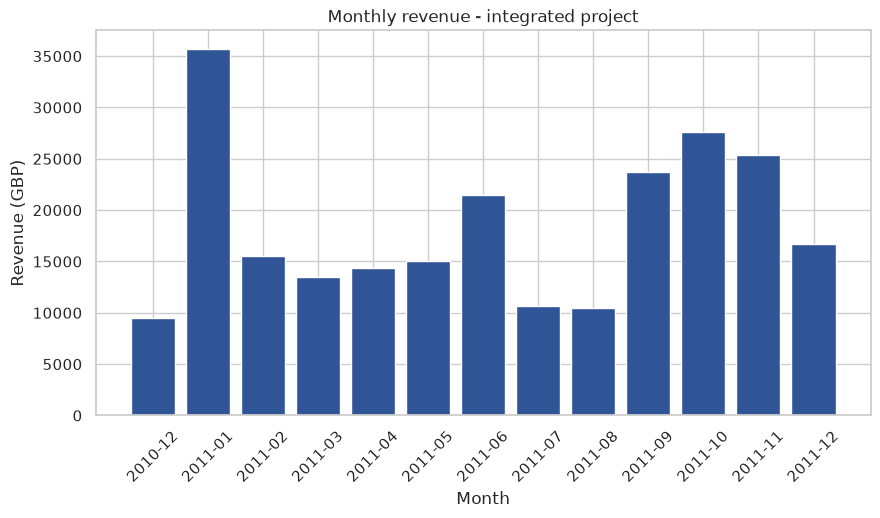

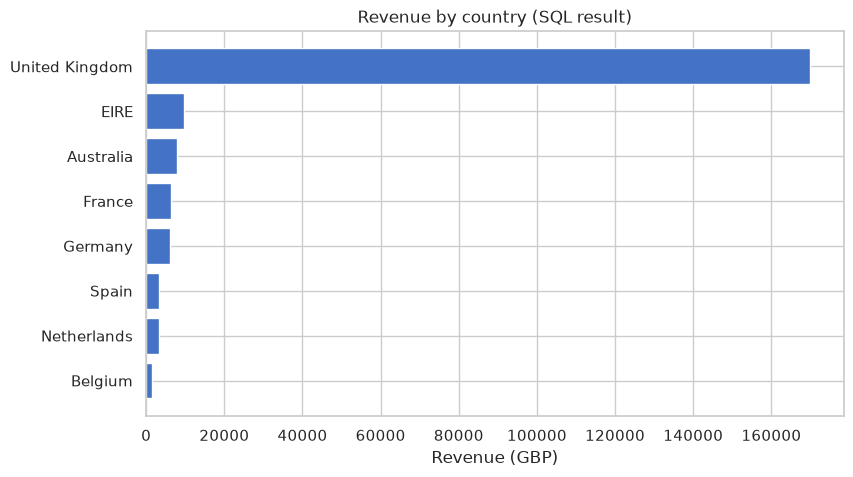

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
monthly_plot = df.groupby("month")["revenue"].sum()
ax.bar(monthly_plot.index, monthly_plot.values, color="#2F5597")
ax.set_title("Monthly revenue - integrated project")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (GBP)")
ax.tick_params(axis="x", rotation=45)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
top = country.sort_values("revenue_gbp")
ax.barh(top["country"], top["revenue_gbp"], color="#4472C4")
ax.set_title("Revenue by country (SQL result)")
ax.set_xlabel("Revenue (GBP)")
plt.show()

## Stage 7 · Power BI dashboard
Power BI Desktop is Windows-only, so the `.pbix` is a documented manual build rather than a fabricated file. `PowerBI_Lab/` contains:

* `power_query_m.m` - the six Power Query queries
* `dax_measures.dax` - the full measure set
* `data_model.md` - the star schema and relationships
* `PowerBI_Business_Analytics_BUILD_GUIDE.md` - click-by-click build steps

The guide states the expected KPI values so the build can be validated against the numbers produced here.

## Stage 8-9 · Documented workflow and version control
* `Jupyter_Lab/Jupyter_Analytics_Workflow.ipynb` - the reproducible notebook (executed, 0 errors).
* `Git_GitHub_Lab/` - the exact `git` command sequence, a real commit history with branches and merges, and a `.gitignore`.
* `.gitignore` in the project root excludes caches and large binaries.

## Stage 10 · Business findings and recommendations
Every figure below was produced by the tools above from the same data.

In [7]:
total = df["revenue"].sum()
uk = df.loc[df["Country"] == "United Kingdom", "revenue"].sum()
cust = df.dropna(subset=["CustomerID"]).groupby("CustomerID")["revenue"].sum()
top20_share = cust.sort_values(ascending=False).head(int(len(cust) * 0.2)).sum() / cust.sum()
peak = monthly_plot.idxmax()
high_value_rate = df["high_value"].mean()

print(f"Total revenue                 GBP {total:,.2f}")
print(f"UK share of revenue           {uk / total:.1%}")
print(f"Top 20% of customers generate {top20_share:.1%} of registered revenue")
print(f"Peak month                    {peak} (GBP {monthly_plot.max():,.2f})")
print(f"Lines over GBP 50            {high_value_rate:.1%}")

Total revenue                 GBP 239,642.62
UK share of revenue           82.0%
Top 20% of customers generate 59.7% of registered revenue
Peak month                    2011-01 (GBP 35,715.76)
Lines over GBP 50            6.3%


**Recommendations**

1. **Protect the UK base, grow international.** The UK accounts for the large majority of revenue; the top overseas markets are small but high-value, so they warrant targeted account management.
2. **Build a retention programme for the top 20%.** A fifth of customers generates the bulk of registered revenue, so losing a handful of accounts moves the headline number.
3. **Plan for the January sample peak.** Revenue peaks in January 2011; inventory, staffing and fulfilment should scale ahead of it.
4. **Review the long tail.** Most lines are under GBP 20, so delivery and payment costs per line matter more than basket size.
5. **Close the guest-checkout gap.** 2,698 lines in the sample have no customer ID, which limits retention marketing.